[2026-11-13 Fiddler](https://thefiddler.substack.com/p/bouncing-billiards)
====================

Fiddler
-------
From symmetry, consider only trajectories that initially go right.

Let $\theta$ be the angle of the initial direction, where $\theta = 0$ hits the red ball straight on.

Let $\theta_1 = \arcsin(2/5)$ be the angle at which the cue ball grazes the red ball before hitting the wall.

Let $\theta_2$ and $\theta_3$ be the angles at which the cue ball grazes the red ball after bouncing
off the right wall once.

The probability of success is $(\theta_1 + \theta_3 - \theta_2)/\pi$.

If the initial direction is $\theta$, the cue ball bounces off the right wall at $\tan\theta = 4/y_r$.
At the bounce, the distance between the centers of the balls is $r_r = \sqrt{16+(5-y_r)^2}$.

Let $\tan\alpha_r = 4/(5-y_r)$, then the solutions to $\alpha_r - \theta = \pm\arcsin(2/r_r)$ are
$\theta_2$ and $\theta_3$.

Visually, $\theta_2 \approx 0.79$ and $\theta_3 \approx 1.22$.

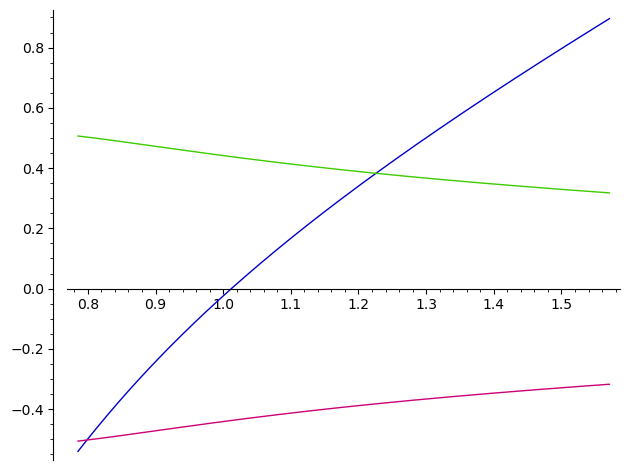

In [1]:
theta = var("theta")
yr = 4/tan(theta)
rr = sqrt(16+(5-yr)^2)
alphar = arctan(4/(5-yr))
theta1, theta2, theta3 = (arcsin(2/5),
                          find_root(alphar-theta - arcsin(2/rr), 0.7, 0.9),
                          find_root(alphar-theta + arcsin(2/rr), 1.1, 1.3))
plot([theta - alphar,arcsin(2/rr),-arcsin(2/rr)], theta, pi/4, pi/2)

The probability of hitting the red ball with no bounces is approximately 13.1%,
and the probability of hitting the red ball after one bounce is approximately 13.6%,
and the probability of hitting the red ball after no more than one bounce is
approximately 26.7%.

In [2]:
p0 = theta1/pi
p1 = (theta3-theta2)/pi
numerical_approx(p0),numerical_approx(p1),numerical_approx(p0+p1)

(0.130989880434455, 0.135995092197517, 0.266984972631972)

Extra credit
------------
When $0 < \theta < \theta_1$, the red ball will be hit with no bounces.

When $\theta_1 < \theta < \theta_2$, it's more complicated.

When $\theta_2 < \theta < \theta_3$, the red ball will be hit after 1 bounce off the right wall.

When $\theta_3 < \theta < \pi/2$, the distance between the center of the cue ball at consecutive
transversals of $x = 0$ is much less than 4, so the red ball will be hit after 2 or more bounces
off the side walls.

When $\pi/2 < \theta < \pi$, the red ball will not be hit.

When $\theta_1 < \theta < \arctan(4/9)$, the first bounce will be off the top wall, the
second bounce will be off the right wall, and the red ball will not be hit.

When $\arctan(4/9) < \theta < \theta_4$, the first bounce will be off the right wall,
the second bounce will be off the top wall, and then the cue ball passes the red ball on its right
without hitting it.

When $\theta_4 < \theta < \theta_5$, the cue ball will bounce off the right wall, then
bounce off the top wall, then hit the red ball.

When $\theta_5 < \theta < \theta_6$, the cue ball will bounce off the right wall, then
bounce off the top wall, then pass the red ball on its left without hitting it.  As $\theta$
increases from $\theta_5$, the top wall is too close to the red ball for the cue ball to
hit the left wall before hitting the top wall.

When $\theta_6 < \theta < \theta_2$, the cue ball will bounce off the right wall, the top
wall, and the left wall before hitting the red ball.  If $\theta_6 > \theta_2$, then this
doesn't happen.

The probability of success is $(\theta_1 + \theta_5 - \theta_4 + \pi/2 - \theta_6)/\pi$.

If the initial direction is $\theta$ and the first bounce is off the right wall at $y_b = 4/\tan\theta$,
the second bounce off the top wall is at $x_t = 4 - (9 - y_b)\tan\theta$.  At the second bounce,
the distance between the centers of the balls is $r_t = \sqrt{16 + x_t^2}$.

Let $\cos\alpha_t = 4/r_t$, then the solutions to $\alpha_t - \theta = \pm \arcsin(2/r_t)$ are
$\theta_4$ and $\theta_5$.

Visually, $\theta_4 \approx 0.42$ and $\theta_5 \approx 0.68$.  The kink in the curve is at $\tan\theta = 8/9$,
where $x_t$ and $\alpha_t$ change sign, and the equation becomes invalid.

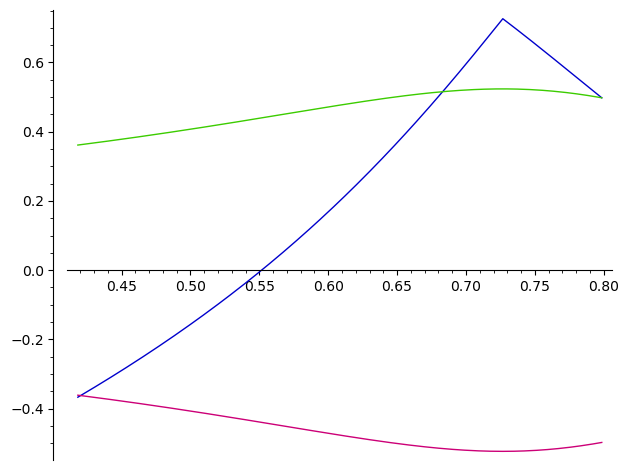

In [3]:
xt = 4 - (9 - yr)*tan(theta)
rt = sqrt(16 + xt^2)
alphat = arccos(4/rt)
theta4, theta5 = (find_root(theta-alphat + arcsin(2/rt), 0.4, 0.45),
                  find_root(theta-alphat - arcsin(2/rt), 0.65, 0.7))
plot([theta-alphat, arcsin(2/rt), -arcsin(2/rt)], theta, arctan(4/9), theta2)

If the ball then bounces off the left wall at $y_l = 9 - (x_t + 4)/\tan\theta$,
the distance between the centers of the balls is $r_l = \sqrt{16 + (y_l - 5)^2}$.

Let $\sin\alpha_l = 4/r_l$.  Then, $\theta_6$ is the solution to $\alpha_l - \theta = \arcsin(2/r_l)$.

Visually, $\theta_6 \approx 0.79$.

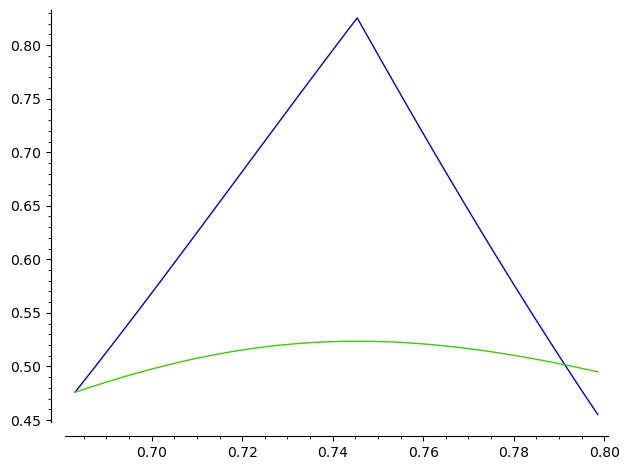

In [4]:
yl = 9 - (xt + 4)/tan(theta)
rl = sqrt(16 + (yl-5)^2)
alphal = arcsin(4/rl)
theta6 = find_root(theta - alphal + arcsin(2/rl), 0.78, 0.80)
plot([alphal - theta, arcsin(2/rl)], theta, theta5, theta2)

The probability of hitting the red ball after bouncing off the right wall, then bouncing off the top wall,
is approximately 8.4%.  The probability of hitting the red ball after bouncing off the right wall, bouncing
off the top wall, then bouncing off the left wall is approximately 0.23%.  The probability of hitting the
red ball after bouncing off both the left and right walls is approximately 11.0%.  The probability of hitting
the red ball after bouncing and the probability of hitting the red ball is approximately 46.3%.

In [5]:
p2 = (theta5-theta4)/pi
p3 = (theta2-theta6)/pi
pn = (pi/2-theta3)/pi
numerical_approx(p2), numerical_approx(p3), numerical_approx(pn), numerical_approx(p0+p2+p3+p1+pn)

(0.0836532217033853, 0.00231211567958569, 0.109810138390594, 0.462760448405537)